# Machine Learning Case Study: Retail Outlet Location Clustering
**Course**: B.Tech Computer Science & Engineering (Semester V)  
**Domain**: Unsupervised Machine Learning, Spatial Retail Analytics, & Dimensionality Reduction  

---

## 1. Problem Statement & Objectives
A commercial retail enterprise is planning an aggressive geographic expansion. To allocate capital efficiently and select suitable store formats (e.g., flagship boutiques vs. convenience kiosks vs. big-box warehouses), the management must segment candidate real estate locations based on **6 key socio-economic and spatial features**:
1. `population_density`: Catchment demographic density (people/km²).
2. `avg_household_income`: Mean annual household purchasing power ($/year).
3. `competitor_count`: Density of direct retail competitors within 2 km.
4. `footfall_estimate`: Daily pedestrian transit volume.
5. `rental_cost`: Monthly real estate leasing cost ($/sq. ft./month).
6. `transport_accessibility`: Multimodal transit connectivity rating (1.0 - 10.0).

### Core Pipeline Steps:
1. **Synthetic Data Synthesis & Statistical Grounding**
2. **Exploratory Data Analysis (EDA) & Outlier Diagnosis**
3. **Handling Missing Values & Feature Scaling Justification**
4. **Optimal Cluster Determination ($K$-Means Elbow, Silhouette, Davies-Bouldin, & Hierarchical Dendrogram)**
5. **Comparative Study: $K$-Means vs. Agglomerative Clustering (ARI & Cross-Tabulation)**
6. **Cluster Stability Validation (Multi-Seed Perturbation & Bootstrap Resampling)**
7. **Dimensionality Reduction via PCA (2D Visual Mapping)**
8. **Business Profiling, Persona Mapping, & Non-Ranking Suitability Analysis**

### Step 1: Environment Setup & Library Imports
We import standard data science and machine learning libraries: `pandas`, `numpy`, `scikit-learn`, `scipy`, `matplotlib`, and `seaborn`.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

# Configure plot styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams.update({
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "figure.titlesize": 14,
    "figure.dpi": 150
})
print("Libraries loaded successfully.")

Libraries loaded successfully.


### Step 2: Loading the Dataset & Examining Missingness
We inspect the dataset structure, feature datatypes, summary statistics, and missing value percentages.

In [2]:
data_path = os.path.join("..", "data", "retail_locations.csv")
if not os.path.exists(data_path):
    data_path = "data/retail_locations.csv"

df = pd.read_csv(data_path)
print("Dataset Shape:", df.shape)
display(df.head())
display(df.info())

# Missing value summary
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage (%)": (df.isnull().sum() / len(df)) * 100
})
display(missing_summary[missing_summary["Missing Count"] > 0])

Dataset Shape: (800, 8)


,population_density,avg_household_income,competitor_count,footfall_estimate,rental_cost,transport_accessibility,location_id,true_archetype
0,12483.0,91100.0,20.0,NaN,101.34,9.6,LOC_0697,Transit-Hub Commercial Zones
1,12532.0,92700.0,11.0,57560.0,65.55,9.5,LOC_0668,Transit-Hub Commercial Zones
2,23318.0,105300.0,16.0,NaN,93.14,8.9,LOC_0064,Dense Premium City-Centre
3,2577.0,52100.0,3.0,4380.0,22.89,4.1,LOC_0534,Low-Density Peripherals
4,14731.0,131200.0,19.0,41570.0,NaN,8.9,LOC_0067,Dense Premium City-Centre


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   population_density       800 non-null    float64
 1   avg_household_income     800 non-null    float64
 2   competitor_count         800 non-null    float64
 3   footfall_estimate        744 non-null    float64
 4   rental_cost              752 non-null    float64
 5   transport_accessibility  800 non-null    float64
 6   location_id              800 non-null    object 
 7   true_archetype           800 non-null    object 
dtypes: float64(6), object(2)
memory usage: 50.1+ KB


None

,Missing Count,Missing Percentage (%)
footfall_estimate,56,7.0
rental_cost,48,6.0


### Step 3: Exploratory Data Analysis (EDA)
We visualize the empirical distributions, outlier presence, and bivariate correlation structure across all 6 features.

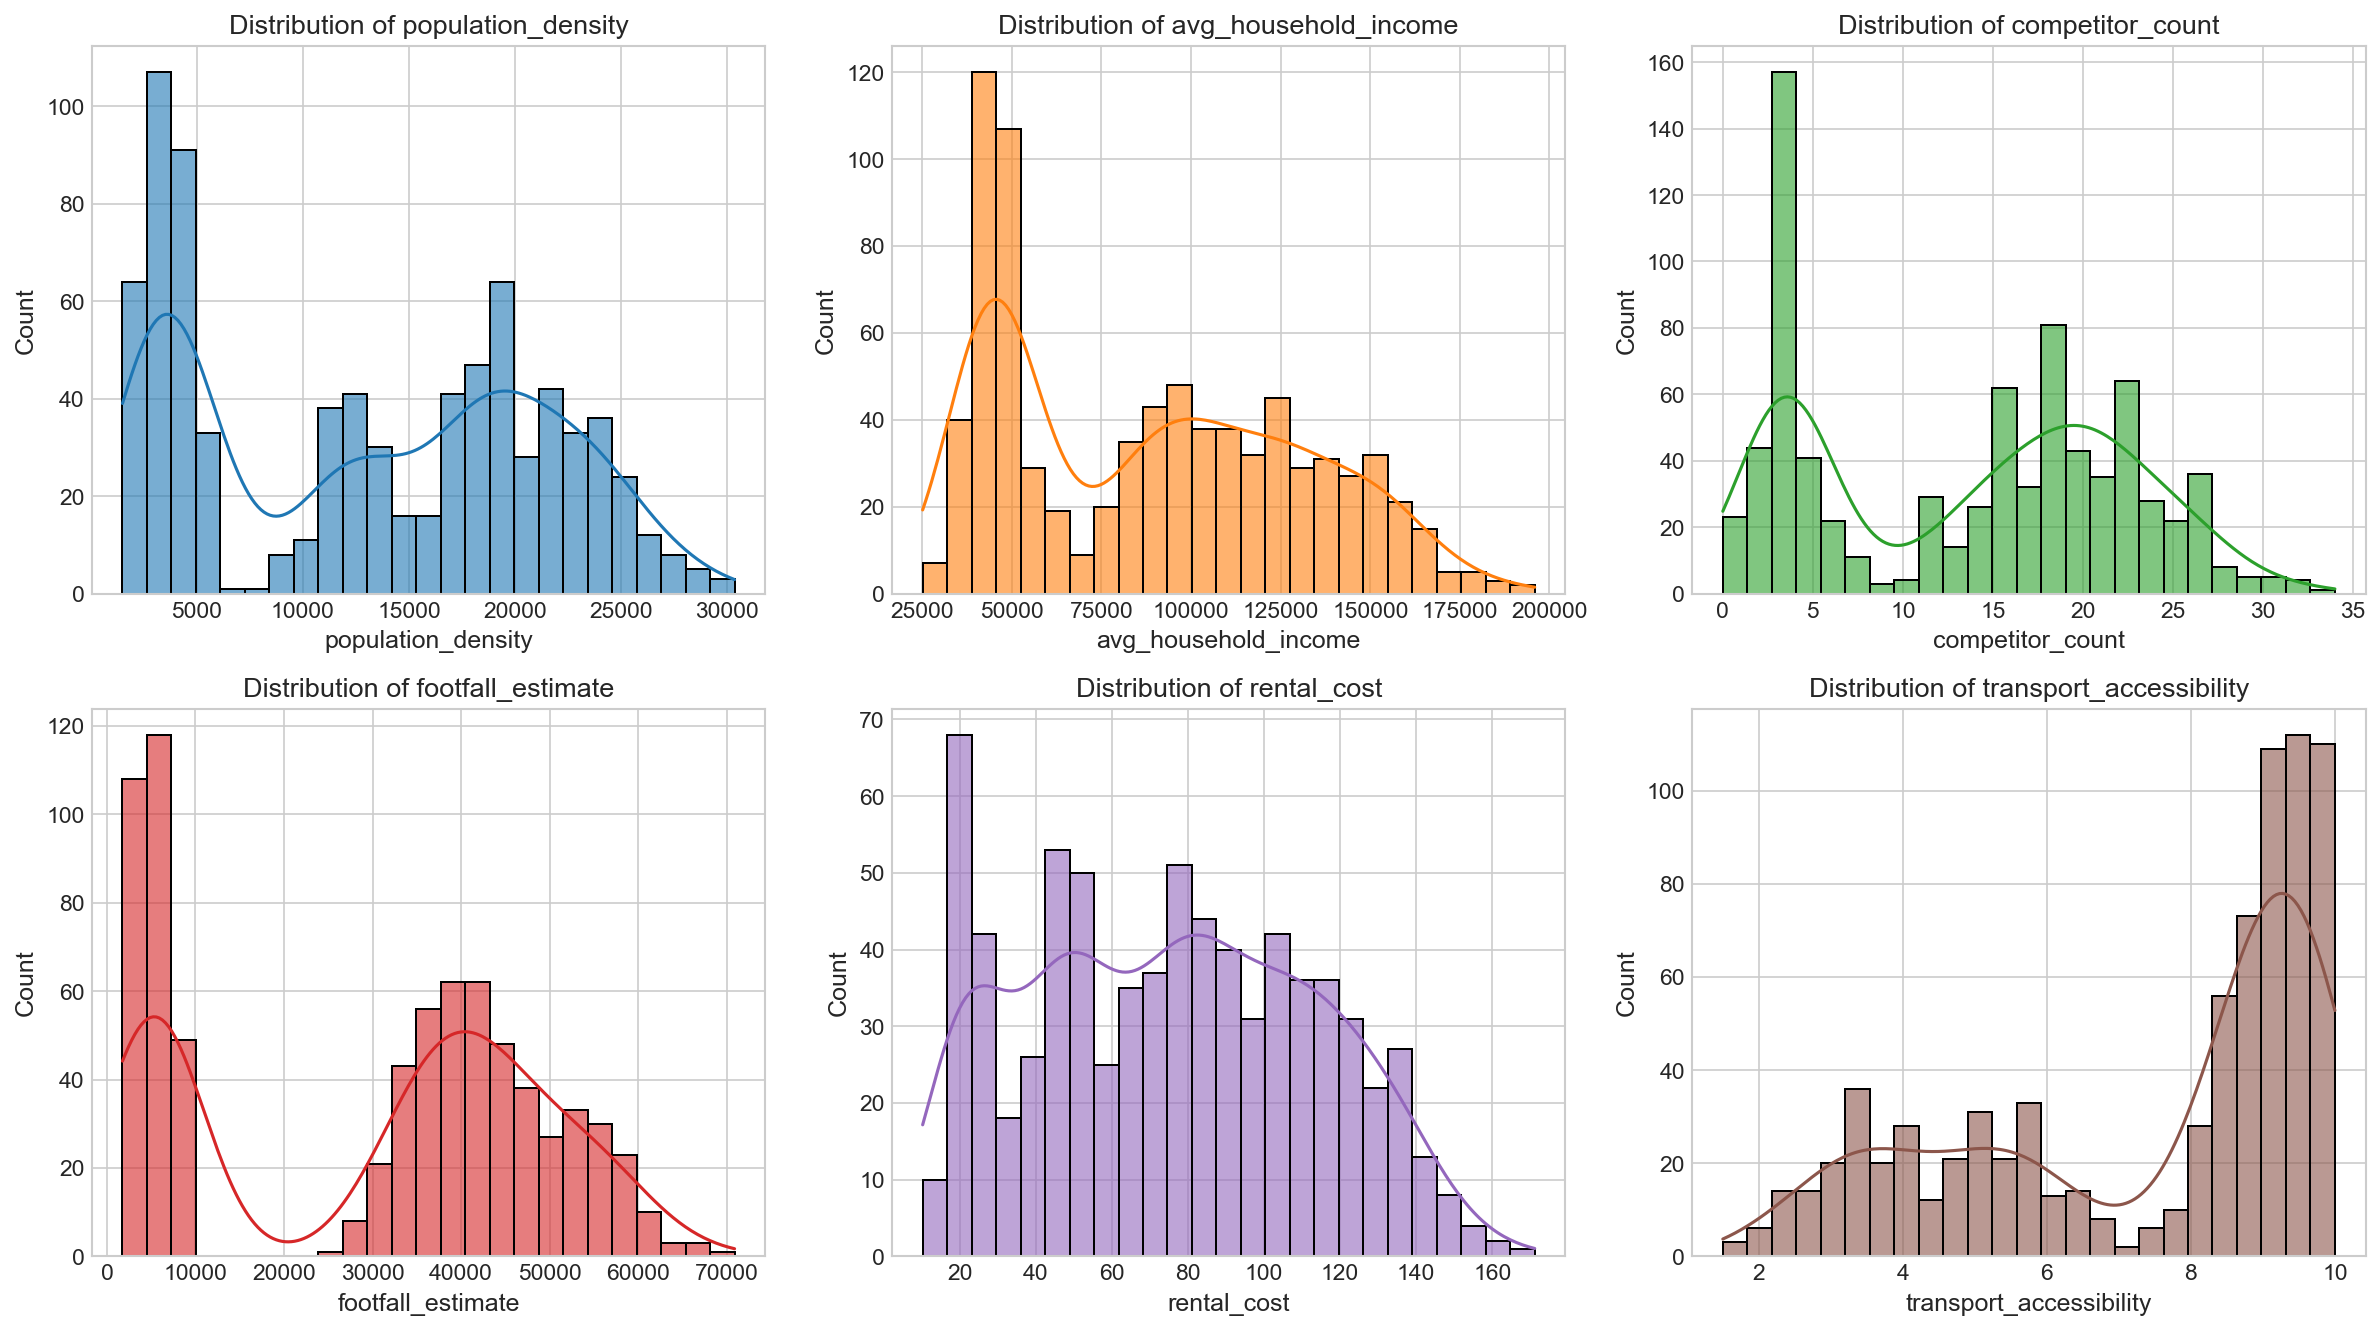

In [3]:
feature_cols = [
    "population_density", "avg_household_income", "competitor_count",
    "footfall_estimate", "rental_cost", "transport_accessibility"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]

for i, col in enumerate(feature_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color=colors[i], bins=25, edgecolor="black", alpha=0.6)
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
plt.tight_layout()
plt.show()

#### Correlation Heatmap
Let's inspect inter-feature linear correlations. Notice the positive relationship between footfall, rental cost, and transit score, reflecting realistic commercial real-estate dynamics.

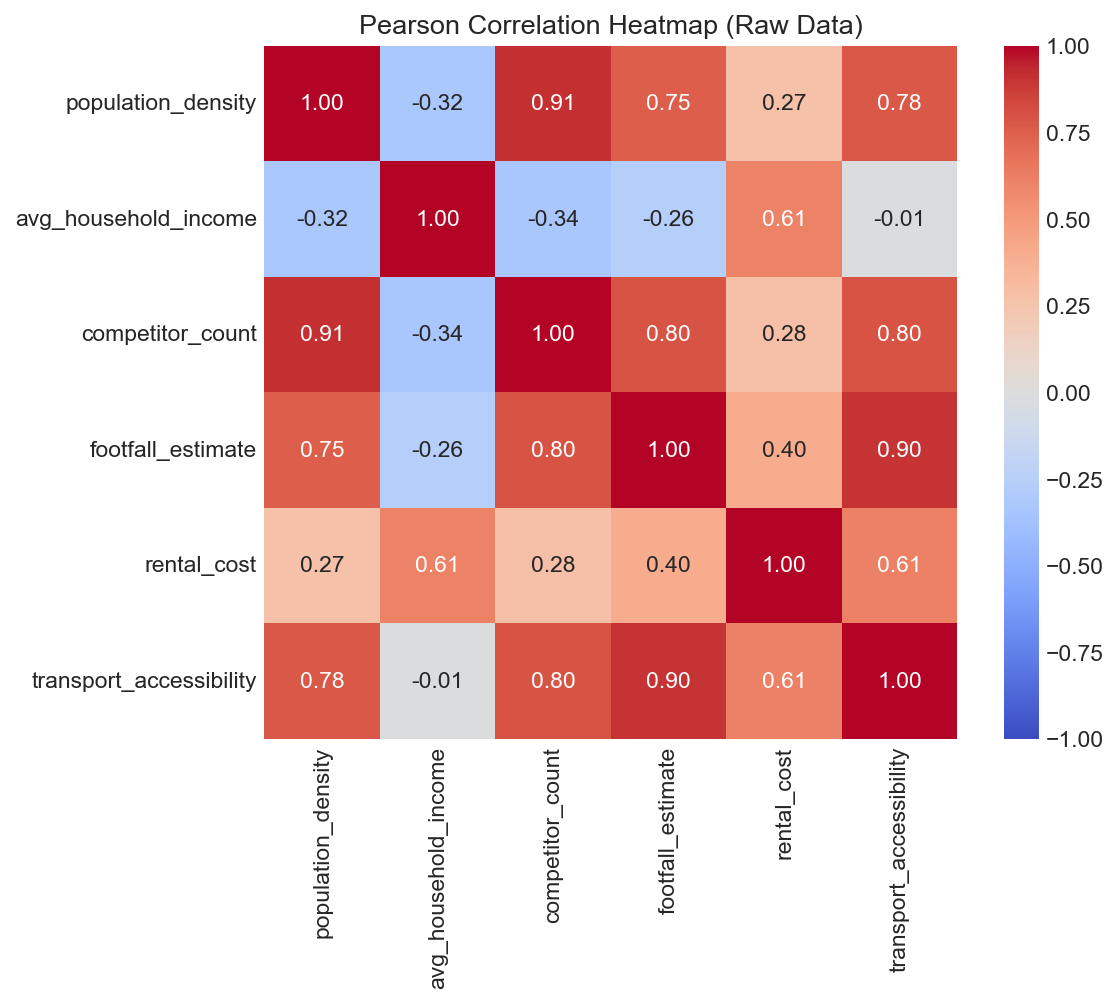

In [4]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[feature_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Pearson Correlation Heatmap (Raw Data)")
plt.show()

### Step 4: Preprocessing & Feature Scaling
1. **Imputation**: We utilize `KNNImputer(n_neighbors=5)` to impute missing footfall and rental values by borrowing information from the closest 5 neighboring locations in multi-attribute space.
2. **Feature Scaling**: Clustering algorithms (K-Means and Hierarchical) rely directly on **Euclidean distance**:
   $$d(p, q) = \sqrt{\sum_{i=1}^n (p_i - q_i)^2}$$
   Without standardization, features with large scales (`avg_household_income` ~ $100,000) will overwhelmingly dominate features on smaller scales (`transport_accessibility` 1-10), skewing the clusters. `StandardScaler` standardizes each feature to mean 0 and std 1.

In [5]:
imputer = KNNImputer(n_neighbors=5)
X_imputed = imputer.fit_transform(df[feature_cols])
df_imputed = pd.DataFrame(X_imputed, columns=feature_cols)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_imputed)
df_scaled = pd.DataFrame(X_scaled, columns=feature_cols)

print("Preprocessed feature matrix shape:", X_scaled.shape)
print("Standardized Mean (approx 0):", np.round(X_scaled.mean(axis=0), 4))
print("Standardized Std Dev (all 1.0):", np.round(X_scaled.std(axis=0), 4))

Preprocessed feature matrix shape: (800, 6)
Standardized Mean (approx 0): [-0.  0. -0. -0.  0.  0.]
Standardized Std Dev (all 1.0): [1. 1. 1. 1. 1. 1.]


### Step 5: Determining the Optimal Number of Clusters ($K$)
We evaluate $K \in [2, 10]$ using:
- **Elbow Method (Within-Cluster Sum of Squares / Inertia)**
- **Silhouette Coefficient**: Measures how well an object is matched to its own cluster compared to neighboring clusters (ranges from -1 to +1).
- **Davies-Bouldin Index**: Lower values indicate better clustering with lower within-cluster scatter and greater separation.

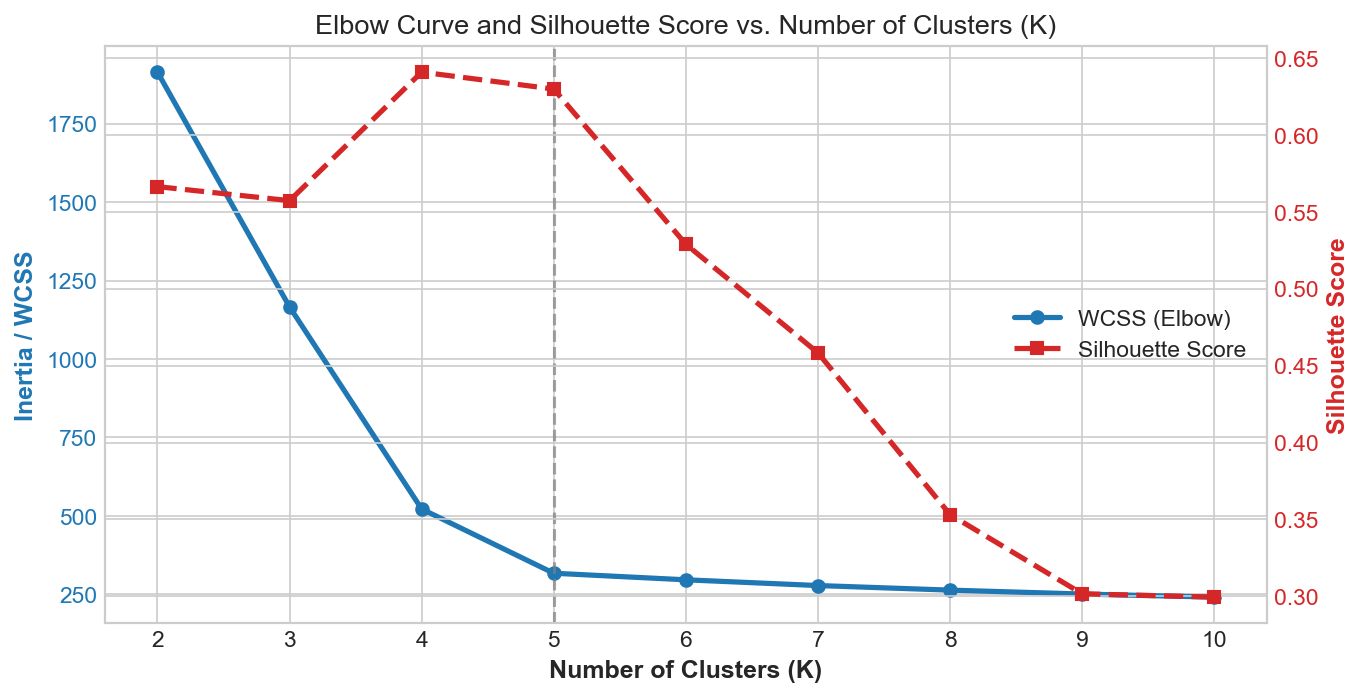

In [6]:
k_range = list(range(2, 11))
wcss = []
silhouette_scores = []
db_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, init="k-means++", n_init=20, random_state=42)
    km.fit(X_scaled)
    wcss.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, km.labels_))
    db_scores.append(davies_bouldin_score(X_scaled, km.labels_))

fig, ax1 = plt.subplots(figsize=(10, 5))
color_wcss = "#1f77b4"
ax1.set_xlabel("Number of Clusters (K)", fontweight="bold")
ax1.set_ylabel("Inertia / WCSS", color=color_wcss, fontweight="bold")
l1 = ax1.plot(k_range, wcss, "o-", color=color_wcss, linewidth=2.5, label="WCSS (Elbow)")
ax1.tick_params(axis="y", labelcolor=color_wcss)
ax1.axvline(x=5, color="gray", linestyle="--", alpha=0.7)

ax2 = ax1.twinx()
color_sil = "#d62728"
ax2.set_ylabel("Silhouette Score", color=color_sil, fontweight="bold")
l2 = ax2.plot(k_range, silhouette_scores, "s--", color=color_sil, linewidth=2.5, label="Silhouette Score")
ax2.tick_params(axis="y", labelcolor=color_sil)

lines = l1 + l2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc="center right")
plt.title("Elbow Curve and Silhouette Score vs. Number of Clusters (K)")
plt.show()

### Step 6: Hierarchical Clustering & Dendrogram Validation
We compute the Ward linkage matrix (minimizing within-cluster variance) and plot the dendrogram to identify the natural cophenetic distance cut.

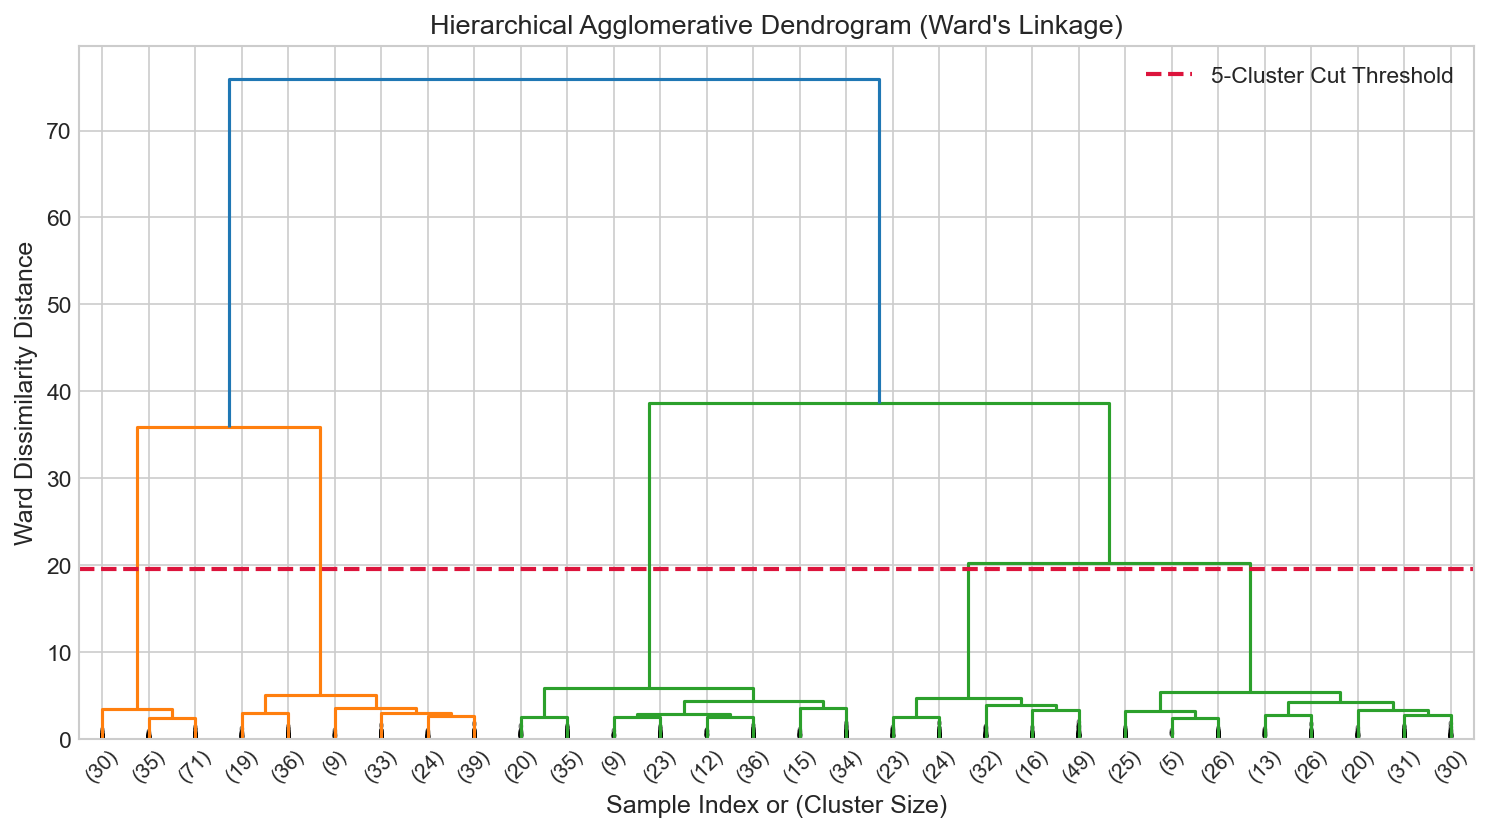

In [7]:
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(12, 6))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=45, leaf_font_size=10, show_contracted=True)
plt.axhline(y=19.5, color="crimson", linestyle="--", linewidth=2, label="5-Cluster Cut Threshold")
plt.title("Hierarchical Agglomerative Dendrogram (Ward's Linkage)")
plt.xlabel("Sample Index or (Cluster Size)")
plt.ylabel("Ward Dissimilarity Distance")
plt.legend(loc="upper right")
plt.show()

### Step 7: Comparative Analysis ($K$-Means vs. Hierarchical Agglomerative)
We fit both models with $K=5$ and compute their **Adjusted Rand Index (ARI)** and cross-tabulation matrix.

In [8]:
kmeans = KMeans(n_clusters=5, init="k-means++", n_init=25, random_state=42)
km_labels = kmeans.fit_predict(X_scaled)

hierarchical = AgglomerativeClustering(n_clusters=5, linkage="ward")
hier_labels = hierarchical.fit_predict(X_scaled)

ari_agreement = adjusted_rand_score(km_labels, hier_labels)
print(f"Adjusted Rand Index (K-Means vs Hierarchical): {ari_agreement:.4f}")

# Cross-tabulation
contingency = pd.crosstab(km_labels, hier_labels, rownames=["K-Means Cluster"], colnames=["Hierarchical Cluster"])
print("Cross-Tabulation Contingency Matrix:")
display(contingency)

Adjusted Rand Index (K-Means vs Hierarchical): 1.0000
Cross-Tabulation Contingency Matrix:


Hierarchical Cluster,0,1,2,3,4
K-Means Cluster,,,,,
0,184,0,0,0,0
1,0,160,0,0,0
2,0,0,176,0,0
3,0,0,0,136,0
4,0,0,0,0,144


### Step 8: Cluster Stability Testing
We test clustering robustness via:
1. **50 Multi-Seed Re-runs**
2. **100 Bootstrap Subsampling Iterations (85% data per run)**

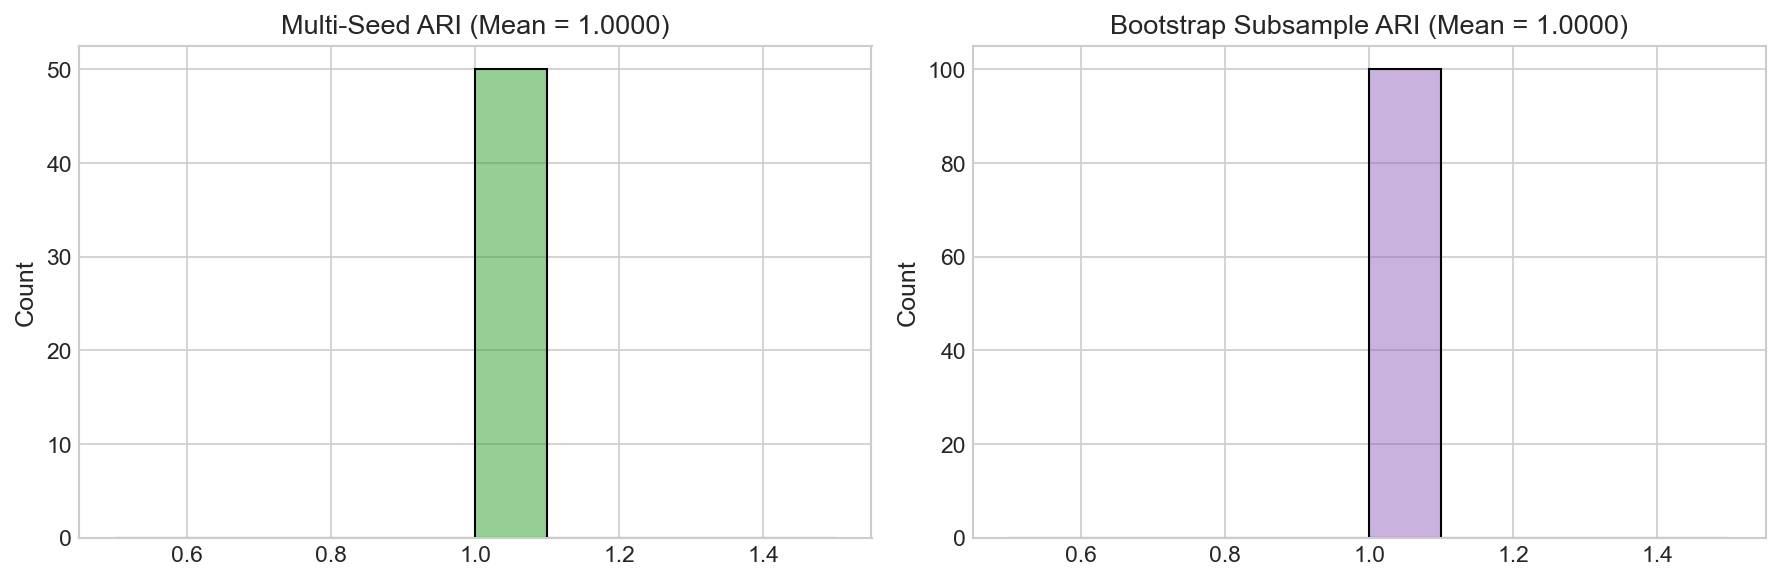

In [9]:
seed_aris = [adjusted_rand_score(km_labels, KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=s).fit_predict(X_scaled)) for s in range(1, 51)]

bootstrap_aris = []
n_pts = len(X_scaled)
for _ in range(100):
    idx = np.random.choice(n_pts, size=int(0.85 * n_pts), replace=False)
    km_b = KMeans(n_clusters=5, init="k-means++", n_init=10, random_state=42)
    b_labels = km_b.fit_predict(X_scaled[idx])
    bootstrap_aris.append(adjusted_rand_score(km_labels[idx], b_labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(seed_aris, bins=10, ax=ax1, color="#2ca02c", kde=True)
ax1.set_title(f"Multi-Seed ARI (Mean = {np.mean(seed_aris):.4f})")
sns.histplot(bootstrap_aris, bins=10, ax=ax2, color="#9467bd", kde=True)
ax2.set_title(f"Bootstrap Subsample ARI (Mean = {np.mean(bootstrap_aris):.4f})")
plt.tight_layout()
plt.show()

### Step 9: PCA Dimensionality Reduction & 2D Cluster Space Visualisation
We reduce the 6D space into 2 Principal Components to visually verify cluster separation and centroid locations.

Explained Variance: PC1 = 62.3%, PC2 = 28.1%, Total = 90.4%


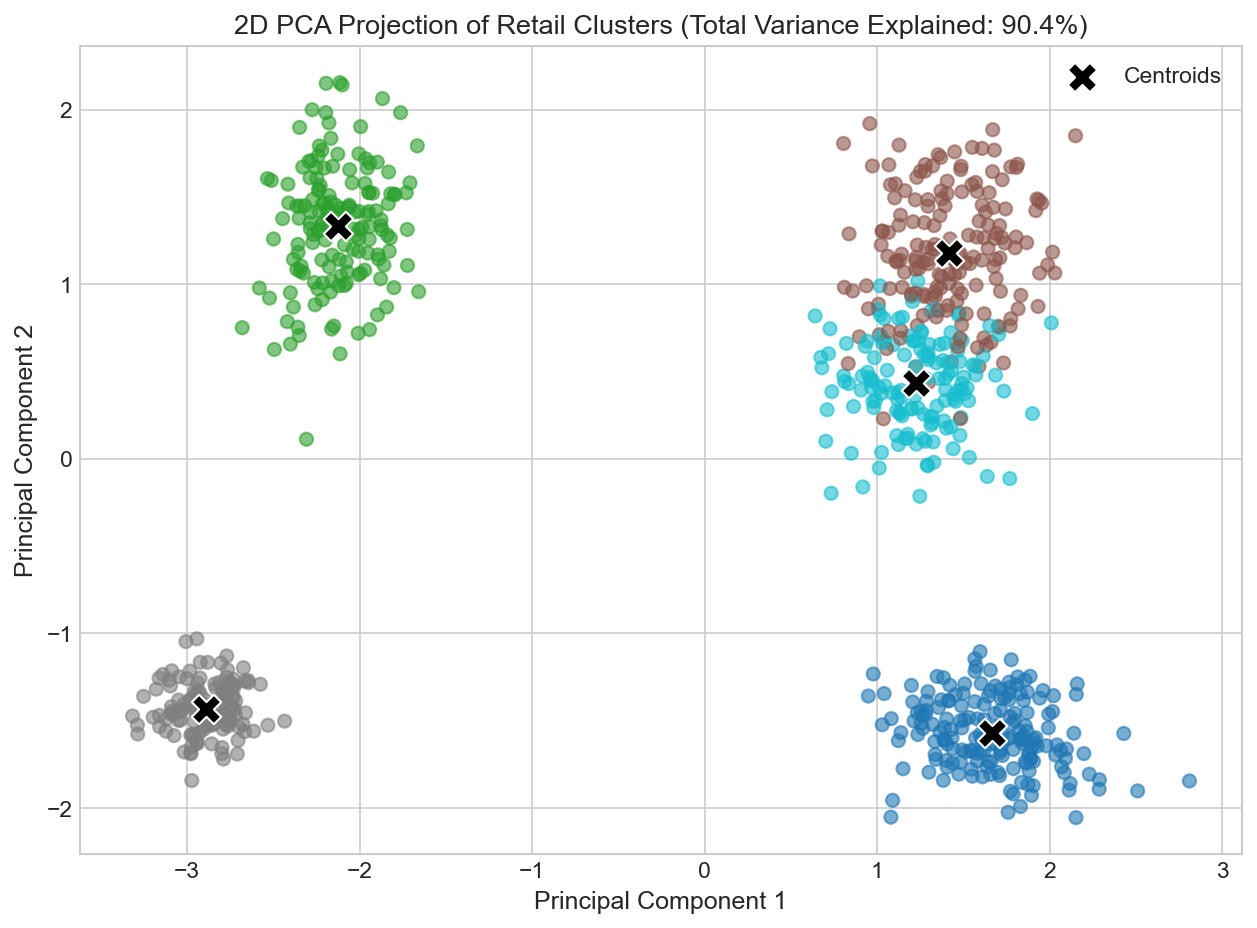

In [10]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
pca_centroids = pca.transform(kmeans.cluster_centers_)

print(f"Explained Variance: PC1 = {pca.explained_variance_ratio_[0]:.1%}, PC2 = {pca.explained_variance_ratio_[1]:.1%}, Total = {sum(pca.explained_variance_ratio_):.1%}")

plt.figure(figsize=(10, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=km_labels, cmap="tab10", alpha=0.6, s=40)
plt.scatter(pca_centroids[:, 0], pca_centroids[:, 1], s=200, c="black", marker="X", edgecolors="white", label="Centroids")
plt.title(f"2D PCA Projection of Retail Clusters (Total Variance Explained: {sum(pca.explained_variance_ratio_):.1%})")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.show()

### Step 10: Cluster Profiling, Persona Tagging, & Expansion Suitability
We compute the unscaled feature means for each cluster and assign intuitive business personas.

> **CRITICAL ANALYTICAL PRINCIPLE**:  
> Clustering groups locations by demographic and spatial similarity; **it does not rank locations by commercial attractiveness**. Commercial viability depends on business format compatibility (e.g., low-rent peripherals suit warehouse discounters, whereas dense city-centres suit luxury flagships).

,population_density,avg_household_income,competitor_count,footfall_estimate,rental_cost,transport_accessibility
Cluster,,,,,,
0,23018.5,42945.1,23.7,43590.9,48.1,8.7
1,4284.2,148841.2,4.0,6710.6,77.4,5.4
2,18792.7,114497.2,19.0,36174.9,124.6,9.2
3,2809.6,49400.0,3.1,3829.5,21.7,3.3
4,12270.0,87004.2,15.0,53050.9,97.6,9.7


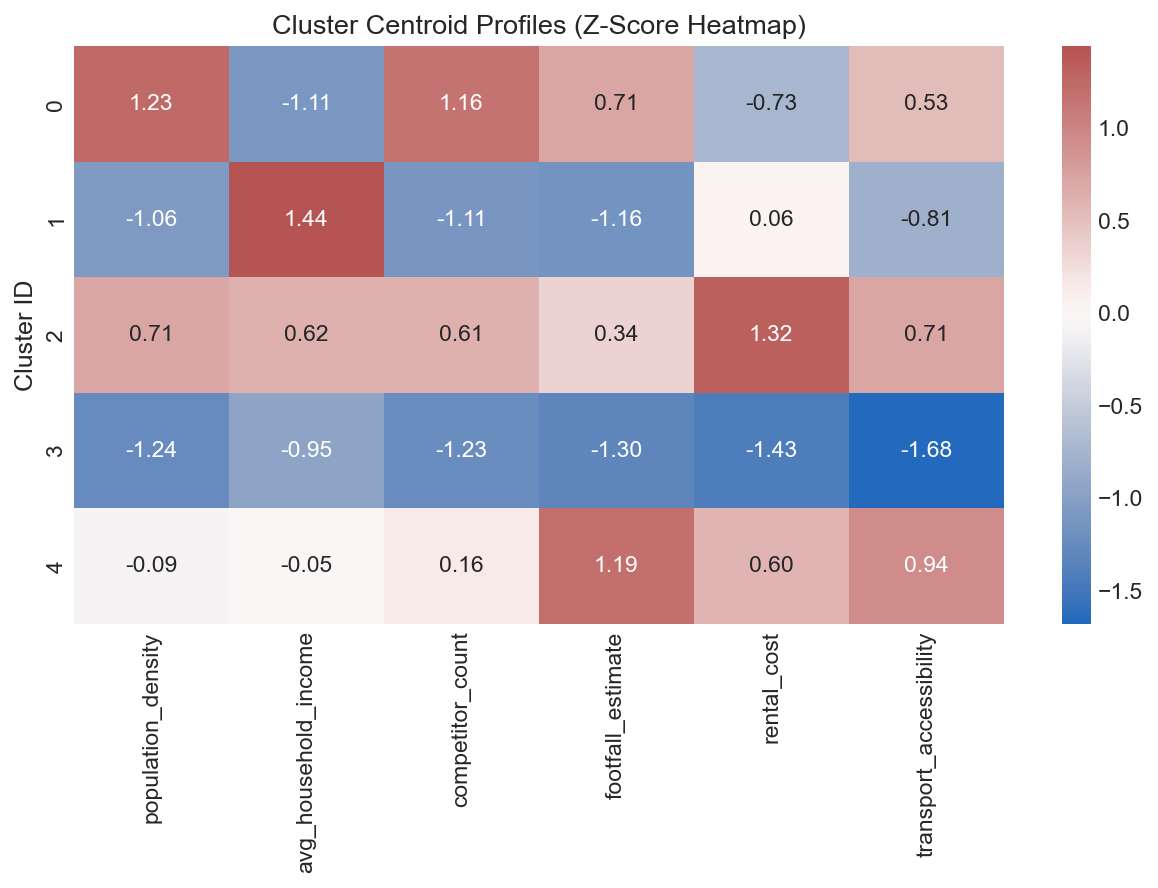

In [11]:
df_imputed["Cluster"] = km_labels
profile_table = df_imputed.groupby("Cluster")[feature_cols].mean().round(1)
display(profile_table)

# Standardized Heatmap Profile
scaled_centroids = pd.DataFrame(kmeans.cluster_centers_, columns=feature_cols)
plt.figure(figsize=(10, 5))
sns.heatmap(scaled_centroids, annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Cluster Centroid Profiles (Z-Score Heatmap)")
plt.ylabel("Cluster ID")
plt.show()